# Demo -- pipeline completo (imagem → YOLO → classificador → cariótipo)

Reproduz o fluxo de ponta a ponta que o `cytoml-demo` vai expor depois (Fase 6), usando só os artefatos já treinados nesta máquina:

1. **Imagem** de uma metáfase (nunca vista em treino/validação de nenhum dos dois modelos).
2. **Detector (YOLO26m)** localiza cada cromossomo -- ele não sabe de qual tipo é, só "aqui tem um cromossomo".
3. **Classificador** decide o tipo (A1...Y) de cada recorte que o detector encontrou.
4. **Pós-processamento** limpa os recortes para a visualização (remove fundo e vizinhos) e deixa cada cromossomo em pé.
5. **Montagem do cariótipo** -- no layout do exame: 4 linhas, pares lado a lado, escala real.
6. **Alerta numérico** -- compara a contagem por classe com o esperado (2 por autossomo, XX/XY) e sinaliza possíveis aneuploidias.

A anotação original (XML) só é usada para conferir o resultado -- em produção (sem XML disponível) as etapas 1-6 rodam exatamente igual.

In [1]:
import sys
from collections import defaultdict
from pathlib import Path

REPO_ROOT = Path("../../..").resolve()
sys.path.insert(0, str(REPO_ROOT / "src" / "classification"))
sys.path.insert(0, str(REPO_ROOT / "src" / "preprocessing"))

import cv2
import numpy as np
import torch
import torch.nn.functional as functional
import matplotlib.pyplot as plt
from ultralytics import YOLO

from dataset import preprocess
from evaluate import load_checkpoint_with_meta
from karyotype import count_by_class, numerical_alerts
from karyogram import plot_karyogram
from postprocess import clean_crop, clean_crop_paper, karyogram_crop
from voc_to_yolo import DENVER_CLASSES, parse_annotation

YOLO_CHECKPOINT = REPO_ROOT / "models" / "yolo" / "yolo26m" / "runs" / "baseline" / "best.pt"
CLASSIFIER_CHECKPOINT = Path("../runs/resnet50-paper/best.pt")  # ajustar pro seu checkpoint

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
detector = YOLO(str(YOLO_CHECKPOINT))
classifier, meta = load_checkpoint_with_meta(CLASSIFIER_CHECKPOINT, device)
print(f"Detector: {YOLO_CHECKPOINT.name}")
print(f"Classificador carregado em {device}: {CLASSIFIER_CHECKPOINT} (resize={meta['resize']})")

Detector: best.pt
Classificador carregado em cuda: ../runs/resnet50-paper/best.pt (resize=stretch)


## Passo 1 -- escolher a imagem

`1060391` é uma das 694 imagens do split de teste com exatamente **46 cromossomos** anotados -- um cariótipo humano completo (23 pares), o cenário mais direto pra avaliar o pipeline. Já vem com o pré-processamento da Fase 1 aplicado (mediana + CLAHE), que é o que os dois modelos esperam como entrada. Pra testar outra imagem com 46 cromossomos, troca `IMAGE_NAME` por qualquer uma da lista impressa abaixo.

Para ver o alerta numérico funcionando, o split de teste também tem metáfases com aneuploidia real (`data/raw/number_abnormalities.csv`) -- por exemplo `1053722` e `1055911` (trissomia do 21) ou `1050431` (trissomia do 18). A lista completa é impressa abaixo.

In [2]:
test_dir = REPO_ROOT / "data" / "processed" / "24_chromosomes_object" / "images" / "test"
raw_annotations_dir = REPO_ROOT / "data" / "raw" / "24_chromosomes_object" / "annotations"

images_with_46 = sorted(
    img.stem
    for img in test_dir.glob("*.jpg")
    if len(parse_annotation(raw_annotations_dir / f"{img.stem}.xml")["objects"]) == 46
)
print(f"{len(images_with_46)} imagens de teste com exatamente 46 cromossomos anotados")

import csv

with open(REPO_ROOT / "data" / "raw" / "number_abnormalities.csv", newline="") as f:
    abnormal = {Path(r["filename"]).stem: r for r in csv.DictReader(f)}
test_names = {p.stem for p in test_dir.glob("*.jpg")}
print("Metáfases com aneuploidia numérica no teste:")
for name in sorted(abnormal.keys() & test_names):
    row = abnormal[name]
    print(f"  {name}: {row['chromosome numbers']} cromossomos, par alterado: {row['description (abnormal chromosome-pair)']}")

IMAGE_NAME = "1060391"

image_path = test_dir / f"{IMAGE_NAME}.jpg"
annotation_path = raw_annotations_dir / f"{IMAGE_NAME}.xml"

image_bgr = cv2.imread(str(image_path))
annotation = parse_annotation(annotation_path)  # só pra conferir acurácia no final
print(f"Imagem: {image_path.name}  ({image_bgr.shape[1]}x{image_bgr.shape[0]}px)")
print(f"Cromossomos anotados (ground truth): {len(annotation['objects'])}")

694 imagens de teste com exatamente 46 cromossomos anotados
Metáfases com aneuploidia numérica no teste:
  1050431: 47 cromossomos, par alterado: 18
  1053722: 47 cromossomos, par alterado: 21
  1055253: 47 cromossomos, par alterado: 18
  1055911: 47 cromossomos, par alterado: 21
  1091594: 46 cromossomos, par alterado: 16
  1091714: 47 cromossomos, par alterado: X
  1101131: 47 cromossomos, par alterado: X
  1101135: 47 cromossomos, par alterado: X
Imagem: 1060391.jpg  (759x619px)
Cromossomos anotados (ground truth): 46


## Passo 2 -- detecção (YOLO)

O detector não usa a anotação em nenhum momento -- só a imagem. Cada caixa é um cromossomo que ele encontrou sozinho.

Cromossomos detectados: 46


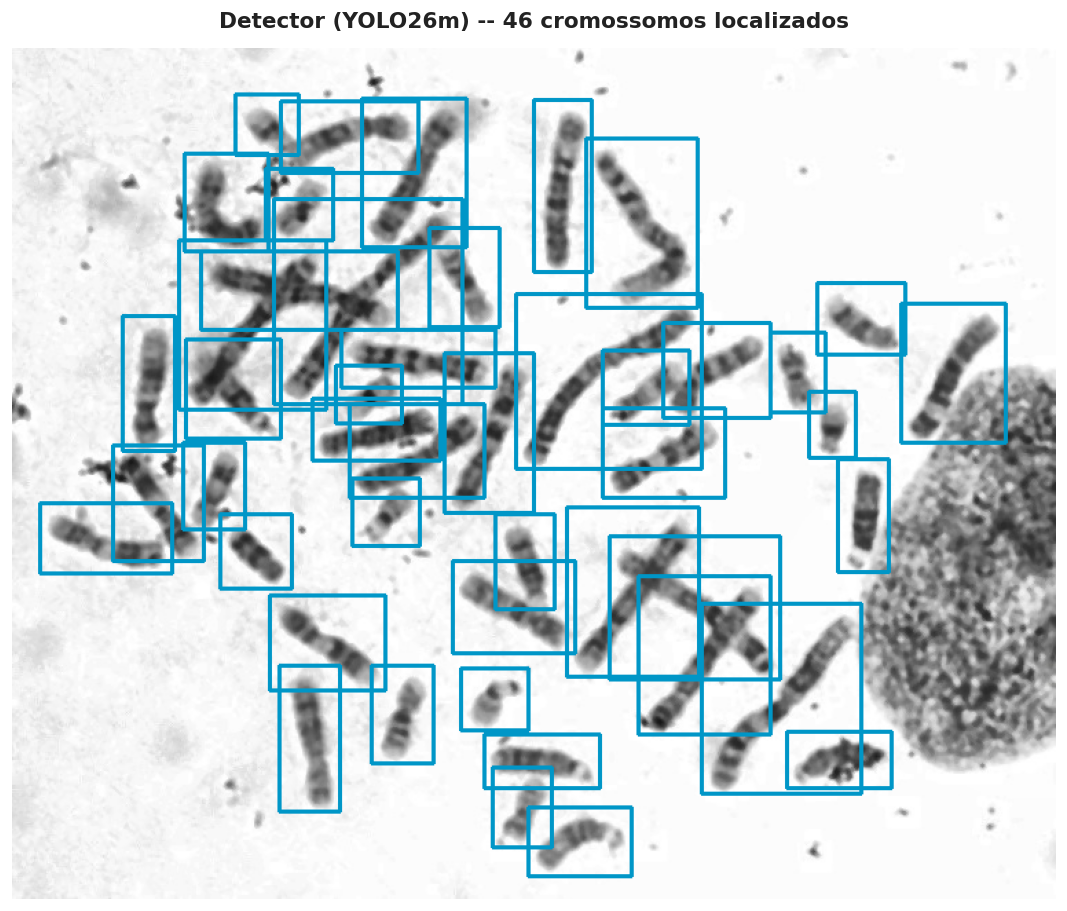

In [3]:
results = detector.predict(str(image_path), verbose=False)[0]
det_boxes = results.boxes.xyxy.cpu().numpy()
det_conf = results.boxes.conf.cpu().numpy()
print(f"Cromossomos detectados: {len(det_boxes)}")

vis = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB).copy()
for (x1, y1, x2, y2) in det_boxes.astype(int):
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 150, 199), 2)

fig, ax = plt.subplots(figsize=(9, 8), dpi=120, facecolor="white")
ax.imshow(vis)
ax.set_title(
    f"Detector (YOLO26m) -- {len(det_boxes)} cromossomos localizados",
    fontsize=13, fontweight="bold", color="#222", pad=12,
)
ax.axis("off")
plt.tight_layout()
plt.show()

## Passo 3 -- classificação de cada recorte

Cada caixa que o detector encontrou vira um recorte independente, que passa pelo classificador (mesmo pré-processamento do treino da run -- escala de cinza + resize 224x224, esticado ou letterbox, lido do checkpoint). O classificador recebe o recorte **cru**: a limpeza do passo 4 é só para a visualização, como no paper.

Pra conferir a acurácia no final, cada detecção é casada (por IoU) com a anotação verdadeira mais próxima -- isso é só pra gerar o relatório, o modelo em si nunca vê a anotação.

In [4]:
def iou_xyxy(a, b):
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    area_a = (ax2 - ax1) * (ay2 - ay1)
    area_b = (bx2 - bx1) * (by2 - by1)
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0


@torch.no_grad()
def predict_crop(image_gray: np.ndarray) -> np.ndarray:
    # mesmo pré-processamento do treino da run (letterbox ou esticado), lido do checkpoint
    tensor = preprocess(image_gray, meta["image_size"], meta["resize"]).unsqueeze(0).to(device)
    logits = classifier(tensor)
    return functional.softmax(logits, dim=1).cpu().numpy()[0]


gt_boxes = [
    (obj["xmin"], obj["ymin"], obj["xmax"], obj["ymax"]) for obj in annotation["objects"]
]
gt_names = [obj["name"] for obj in annotation["objects"]]

# casamento guloso detecção <-> anotação, só para o relatório de acurácia
pairs = sorted(
    (
        (iou_xyxy(det_boxes[di], gt_boxes[gi]), di, gi)
        for di in range(len(det_boxes))
        for gi in range(len(gt_boxes))
    ),
    reverse=True,
)
matched_gt_for_det, used_gt = {}, set()
for score, di, gi in pairs:
    if score < 0.3 or di in matched_gt_for_det or gi in used_gt:
        continue
    matched_gt_for_det[di] = gi
    used_gt.add(gi)

height, width = image_bgr.shape[:2]
entries = []
for di, (x1, y1, x2, y2) in enumerate(det_boxes):
    x1, y1 = max(0, int(x1)), max(0, int(y1))
    x2, y2 = min(width, int(x2)), min(height, int(y2))
    crop = cv2.cvtColor(image_bgr[y1:y2, x1:x2], cv2.COLOR_BGR2GRAY)
    probs = predict_crop(crop)
    pred_name = DENVER_CLASSES[int(probs.argmax())]
    true_name = gt_names[matched_gt_for_det[di]] if di in matched_gt_for_det else None
    entries.append(
        {"image": crop, "pred": pred_name, "true": true_name, "conf": float(probs.max())}
    )

missed = len(gt_boxes) - len(used_gt)
print(f"Classificados: {len(entries)}")
print(f"Anotações sem detecção correspondente (falso negativo do detector): {missed}")

Classificados: 46
Anotações sem detecção correspondente (falso negativo do detector): 0


## Passo 4 -- pós-processamento dos recortes

Antes de montar o cariótipo, cada recorte é limpo: só o cromossomo central fica, o resto (fundo, sujeira, pedaços de vizinhos que caíram dentro da caixa) vira branco. A versão fiel ao paper (Rosas-Alatriste et al., 2026 -- maior contorno via threshold adaptativo + nitidez) falha nos nossos recortes: corta as bandas claras, às vezes escolhe um vizinho ou um fragmento e granula a imagem. Por isso o cariótipo usa a versão adaptada (`postprocess.clean_crop`: threshold de Otsu, objeto do centro, sem nitidez) -- ver a docstring de `src/classification/postprocess.py`. Vizinhos que encostam no cromossomo continuam na imagem; separá-los exigiria segmentação.

Depois da limpeza, cada cromossomo é colocado em pé (`postprocess.karyogram_crop`), com ideias do KarySOM (Marc & Czibula): gira e apara até a orientação "retrato" pelo eixo principal do objeto e, quando o estreitamento do centrômero (a parte mais fina) é nítido, põe o braço curto (p) para cima. Cromossomos curvos ficam em pé, mas continuam curvos.

O painel mostra os recortes desta imagem em que a limpeza mais mudou a imagem.

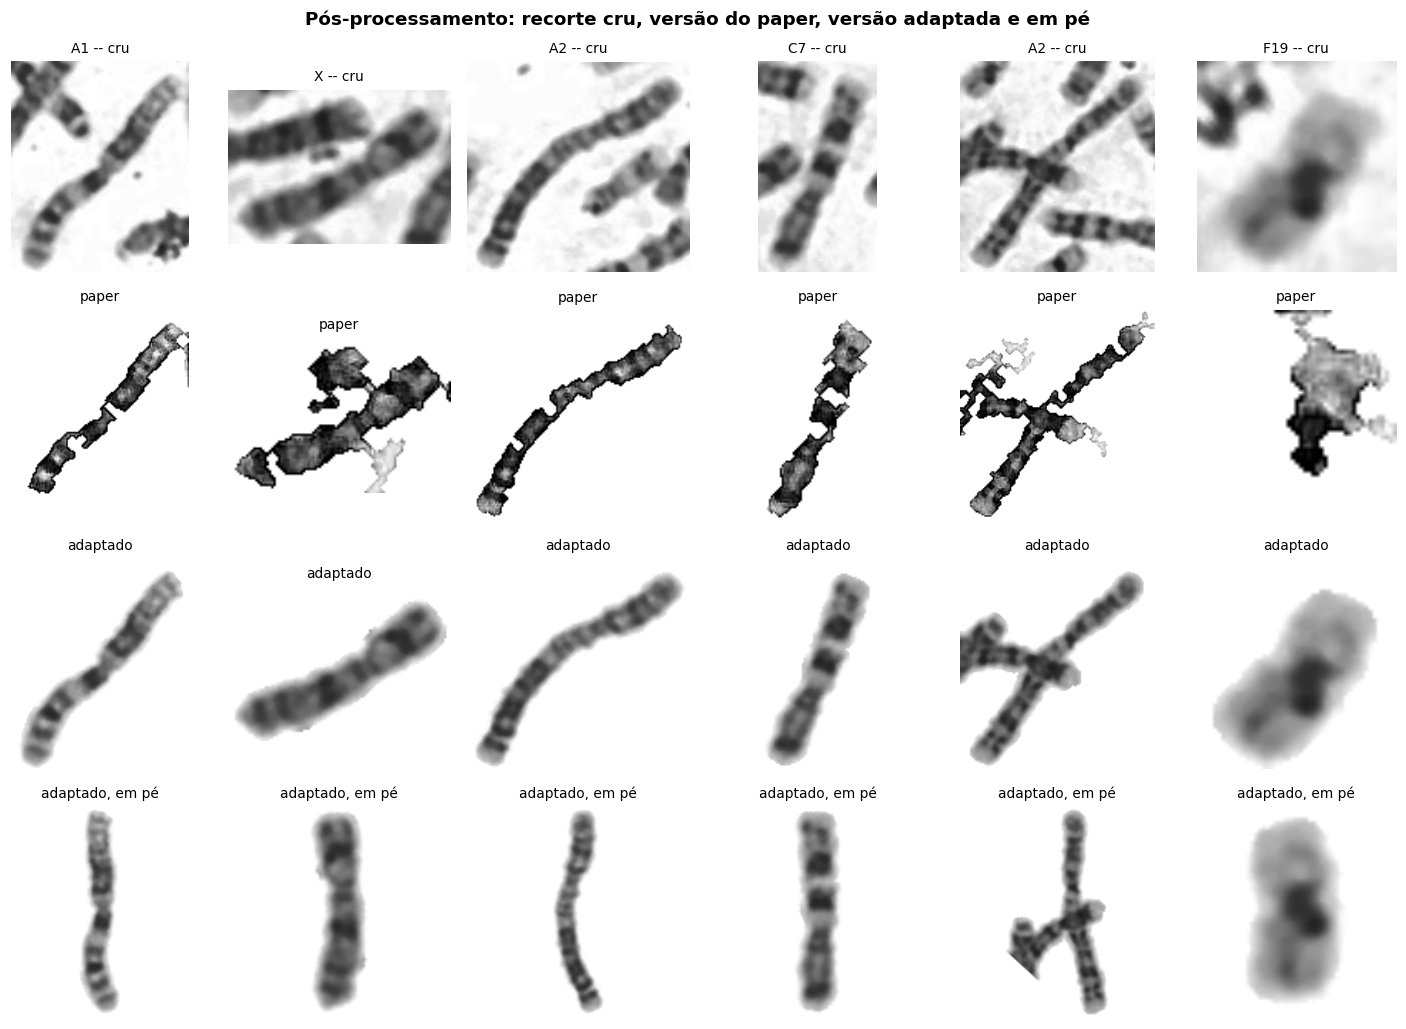

In [5]:
for e in entries:
    e["display"] = karyogram_crop(e["image"])


def dark_pixels(img):
    return int((img < 128).sum())


def removed_fraction(e):
    """Fração dos pixels escuros do recorte que a limpeza removeu."""
    return 1 - dark_pixels(e["display"]) / max(dark_pixels(e["image"]), 1)


shown = sorted(entries, key=removed_fraction, reverse=True)[:6]
fig, axes = plt.subplots(4, len(shown), figsize=(2.2 * len(shown), 9.5), dpi=110, facecolor="white")
for col, e in enumerate(shown):
    variants = [
        (e["image"], "cru"),
        (clean_crop_paper(e["image"]), "paper"),
        (clean_crop(e["image"]), "adaptado"),
        (e["display"], "adaptado, em pé"),
    ]
    for row, (img, title) in enumerate(variants):
        ax = axes[row, col]
        ax.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="bilinear")
        ax.set_title(f"{e['pred']} -- {title}" if row == 0 else title, fontsize=9)
        ax.axis("off")
fig.suptitle("Pós-processamento: recorte cru, versão do paper, versão adaptada e em pé", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## Passo 5 -- montagem do cariótipo

No layout do exame (`src/classification/karyogram.py`): 4 linhas (1-5; 6-12; 13-18; 19-22, Y, X), homólogos lado a lado com o número do par embaixo, todos na mesma escala em pixels da metáfase -- o tamanho relativo (1 grande, 21 pequeno) faz parte da leitura do exame. Os cromossomos são agrupados pela classe **prevista** pelo classificador (é isso que um usuário final veria, sem anotação de apoio). Pares com contagem fora do esperado ficam com o número em vermelho. A conferência com a anotação aparece no subtítulo e no resumo no fim do notebook.

Limitações visíveis: vizinhos que encostam ou cruzam o cromossomo continuam no recorte (separá-los exigiria segmentação de instâncias -- o paper evita o problema descartando metáfases com sobreposição), e a orientação do braço p só é ajustada quando o centrômero é nítido.

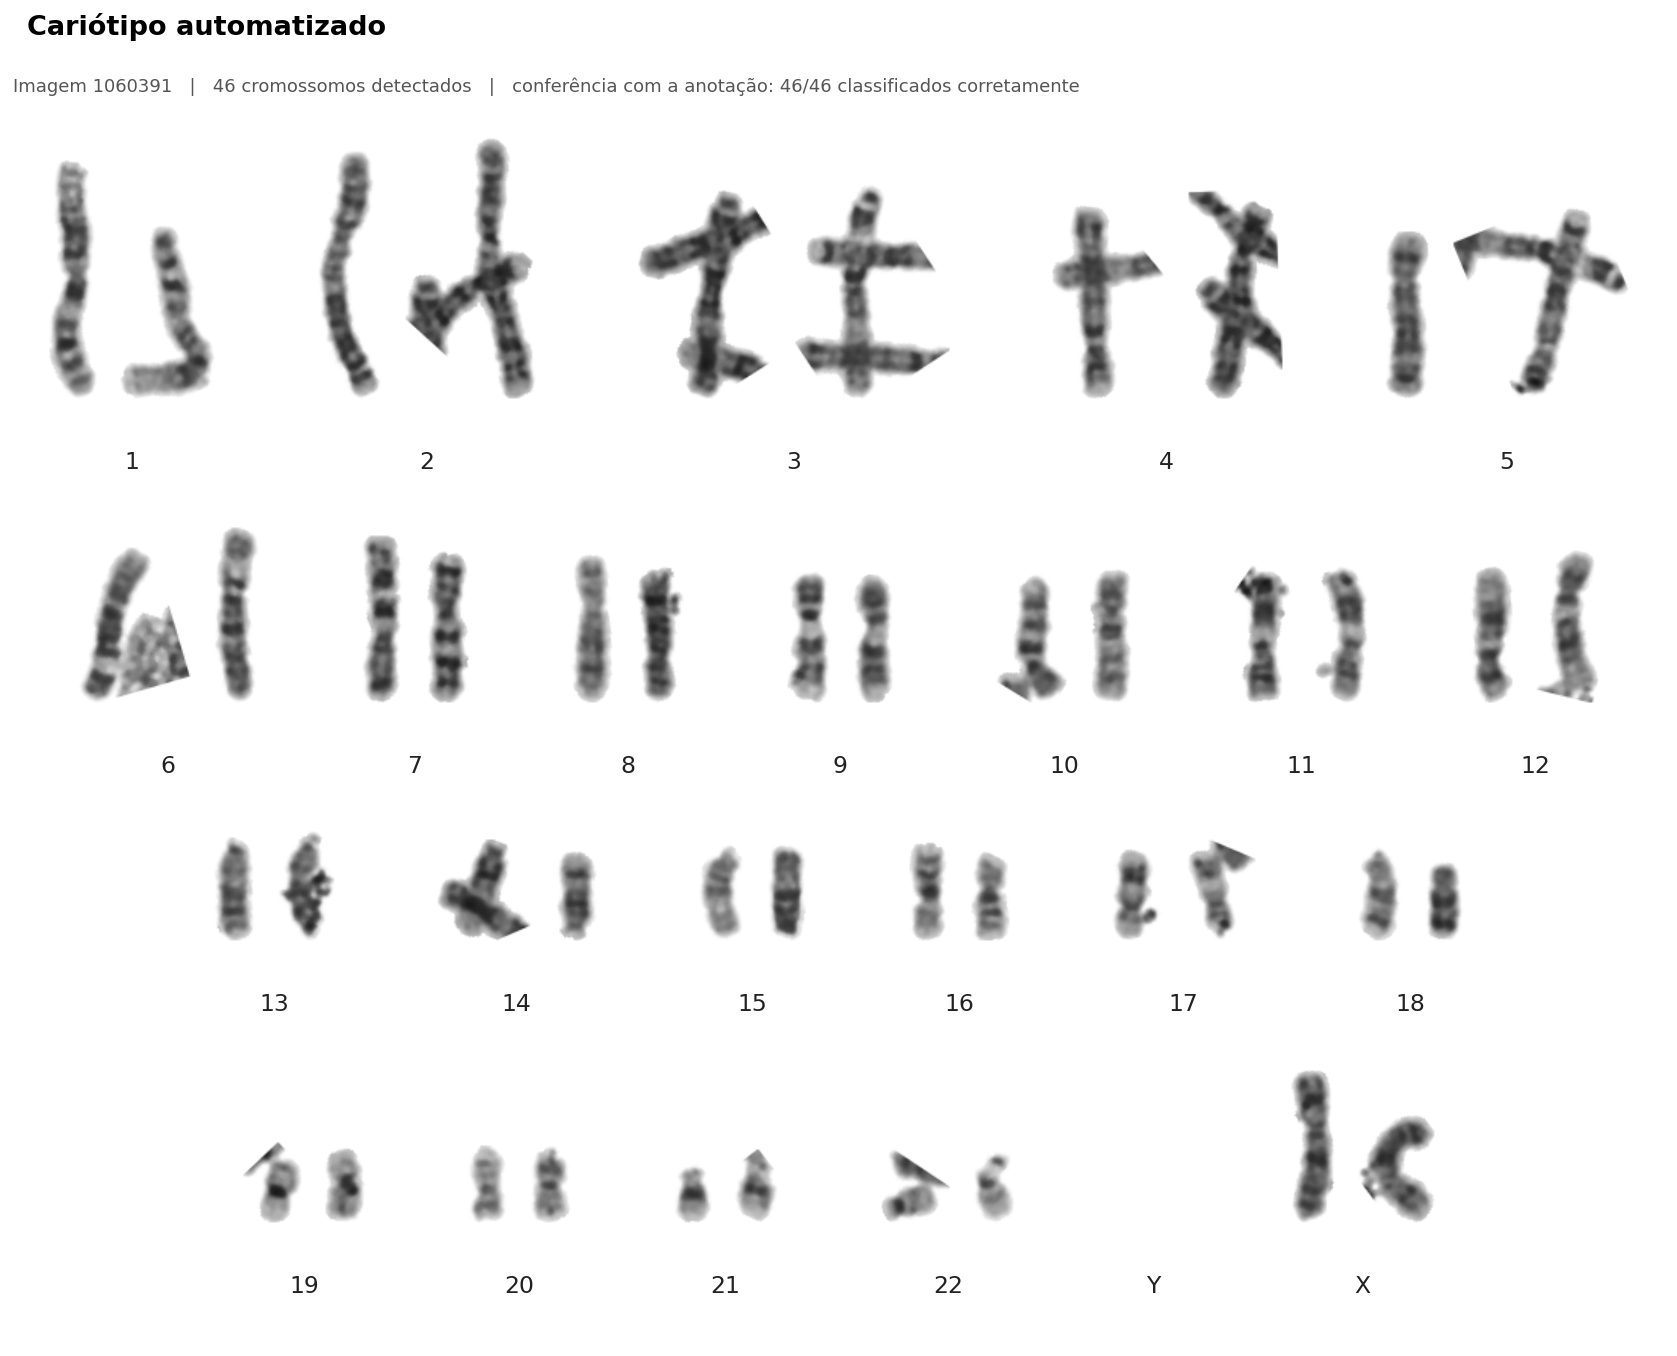

In [6]:
images_by_class = defaultdict(list)
for e in entries:
    images_by_class[e["pred"]].append(e["display"])

alerts = numerical_alerts(count_by_class([e["pred"] for e in entries]))
known = [e for e in entries if e["true"] is not None]
correct = sum(e["pred"] == e["true"] for e in known)

fig = plot_karyogram(
    images_by_class,
    alerts=alerts,
    title="Cariótipo automatizado",
    subtitle=(
        f"Imagem {IMAGE_NAME}   |   {len(entries)} cromossomos detectados   |   "
        f"conferência com a anotação: {correct}/{len(known)} classificados corretamente"
    ),
)
plt.show()

## Passo 6 -- alerta numérico

Conta os cromossomos por classe prevista e compara com o esperado: 2 por autossomo; XY se houver algum Y, senão XX (regra do `karyotype_assembler.py` do paper, em `src/classification/karyotype.py`). A fórmula segue a notação usual (total de cromossomos, cromossomos sexuais). É uma triagem para revisão do especialista, não um diagnóstico -- um erro de classificação também aparece como alerta. A mesma regra aplicada à anotação verdadeira serve de conferência.

In [7]:
def karyotype_formula(counts: dict[str, int]) -> str:
    return f"{sum(counts.values())},{'X' * counts['X']}{'Y' * counts['Y']}"


def describe(alerts: dict) -> str:
    if not alerts:
        return "nenhuma alteração numérica"
    return ", ".join(
        f"{c}: {a['observed']} (esperado {a['expected']})" for c, a in alerts.items()
    )


predicted_counts = count_by_class([e["pred"] for e in entries])
true_counts = count_by_class(gt_names)

print(f"Pipeline:  {karyotype_formula(predicted_counts):<8} -> {describe(numerical_alerts(predicted_counts))}")
print(f"Anotação:  {karyotype_formula(true_counts):<8} -> {describe(numerical_alerts(true_counts))}")
if IMAGE_NAME in abnormal:
    row = abnormal[IMAGE_NAME]
    print(f"Rótulo do dataset: {row['chromosome numbers']} cromossomos, par alterado: {row['description (abnormal chromosome-pair)']}")

Pipeline:  46,XX    -> nenhuma alteração numérica
Anotação:  46,XX    -> nenhuma alteração numérica


## Resumo da classificação

In [8]:
print(f"Cromossomos anotados na imagem: {len(gt_boxes)}")
print(f"Detectados pelo YOLO: {len(det_boxes)}")
print(f"Não detectados (falso negativo do detector): {missed}")
print(f"Classificados corretamente: {correct}/{len(known)} ({correct / len(known):.1%})")

wrong = [e for e in known if e["pred"] != e["true"]]
if wrong:
    print("\nErros de classificação:")
    for e in wrong:
        print(f"  - {e['true']} confundido com {e['pred']} (confiança: {e['conf']:.0%})")

Cromossomos anotados na imagem: 46
Detectados pelo YOLO: 46
Não detectados (falso negativo do detector): 0
Classificados corretamente: 46/46 (100.0%)
